## Parse frames from video

In [14]:
%%bash
mkdir -p frames
if [ -z "$( ls -A 'frames' )" ]; then
    ffmpeg -i original.mp4 -vf fps=24 frames/frame%04d.png
else
    echo Frames folder not empty, skipping
fi

Frames folder not empty, skipping


## Render parameters

In [70]:
HEIGHT = 12
WIDTH = 220
FRAMES = 5258 # 5258
FPS = 1 # 24
GROUP1 = 'AG'
GROUP2 = 'CT'

In [5]:
%%writefile custom.matrix
   A  C  G  T
A  2 -4  2 -4
C -4  2 -4  2
G  2 -4  2 -4
T -4  2 -4  2

Overwriting custom.matrix


## Generate `.fa` files
Be aware that this will empty the `queries` folder. In mode 3, we will also generate `.json` files to indiciate which lines each frame is composed of.

In [14]:
!mkdir -p queries
!rm queries/*.fa
!rm queries/*.json
from query_generator import *
generate_queries_by_line(HEIGHT, WIDTH, FRAMES, FPS, GROUP1, GROUP2)

A subdirectory or file queries already exists.
Error occurred while processing: queries.


Done with 1977 unique lines!                                                  


## Prepare matplotlib canvas

In [196]:
BACKGROUND_COLOR = (0.1, 0.1, 0.1)
TEXT_COLOR = (0.9, 0.9, 0.9)
BASE_COLORS = {
    "A": (0.3, 1.0, 0.5),
    "G": (0.5, 0.8, 0.2),
    "C": (0.2, 0.7, 1.0),
    "T": (0, 0.9, 1.0)
}

In [197]:
class SequenceDraw:
    def __init__(self, fig, y):
        self.name = fig.text(0.36, 1-y/HEIGHT - 0.03, "CM000665.2 Homo sapiens chromosome 3, GRCh38 reference", fontsize=16, color=TEXT_COLOR)
        self.f = fig.text(0, 1-y/HEIGHT - 0.03, "000000000", fontsize=16, color=TEXT_COLOR)
        self.t = fig.text(0.96, 1-y/HEIGHT - 0.03, "000000000", fontsize=16, color=TEXT_COLOR)
        self.sequence = []
        for x in range(WIDTH):
            self.sequence.append(fig.text(x/WIDTH, 1-y/HEIGHT, "N", fontsize=16, color=TEXT_COLOR))

    def write_info(self, name, f, t):
        self.name.set_text(name)
        self.f.set_text(f)
        self.t.set_text(t)
        
    def clear(self):
        for x in range(WIDTH):
            self.draw_char("N", x)
        
    def get_color(self, base):
        return BASE_COLORS.get(base, TEXT_COLOR)
    
    def write_char(self, base, x):
        color = self.get_color(base)
        self.sequence[x].set_text(base)
        self.sequence[x].set_color(color)
        

Text(0.35, 0.78, '(T)hymine')

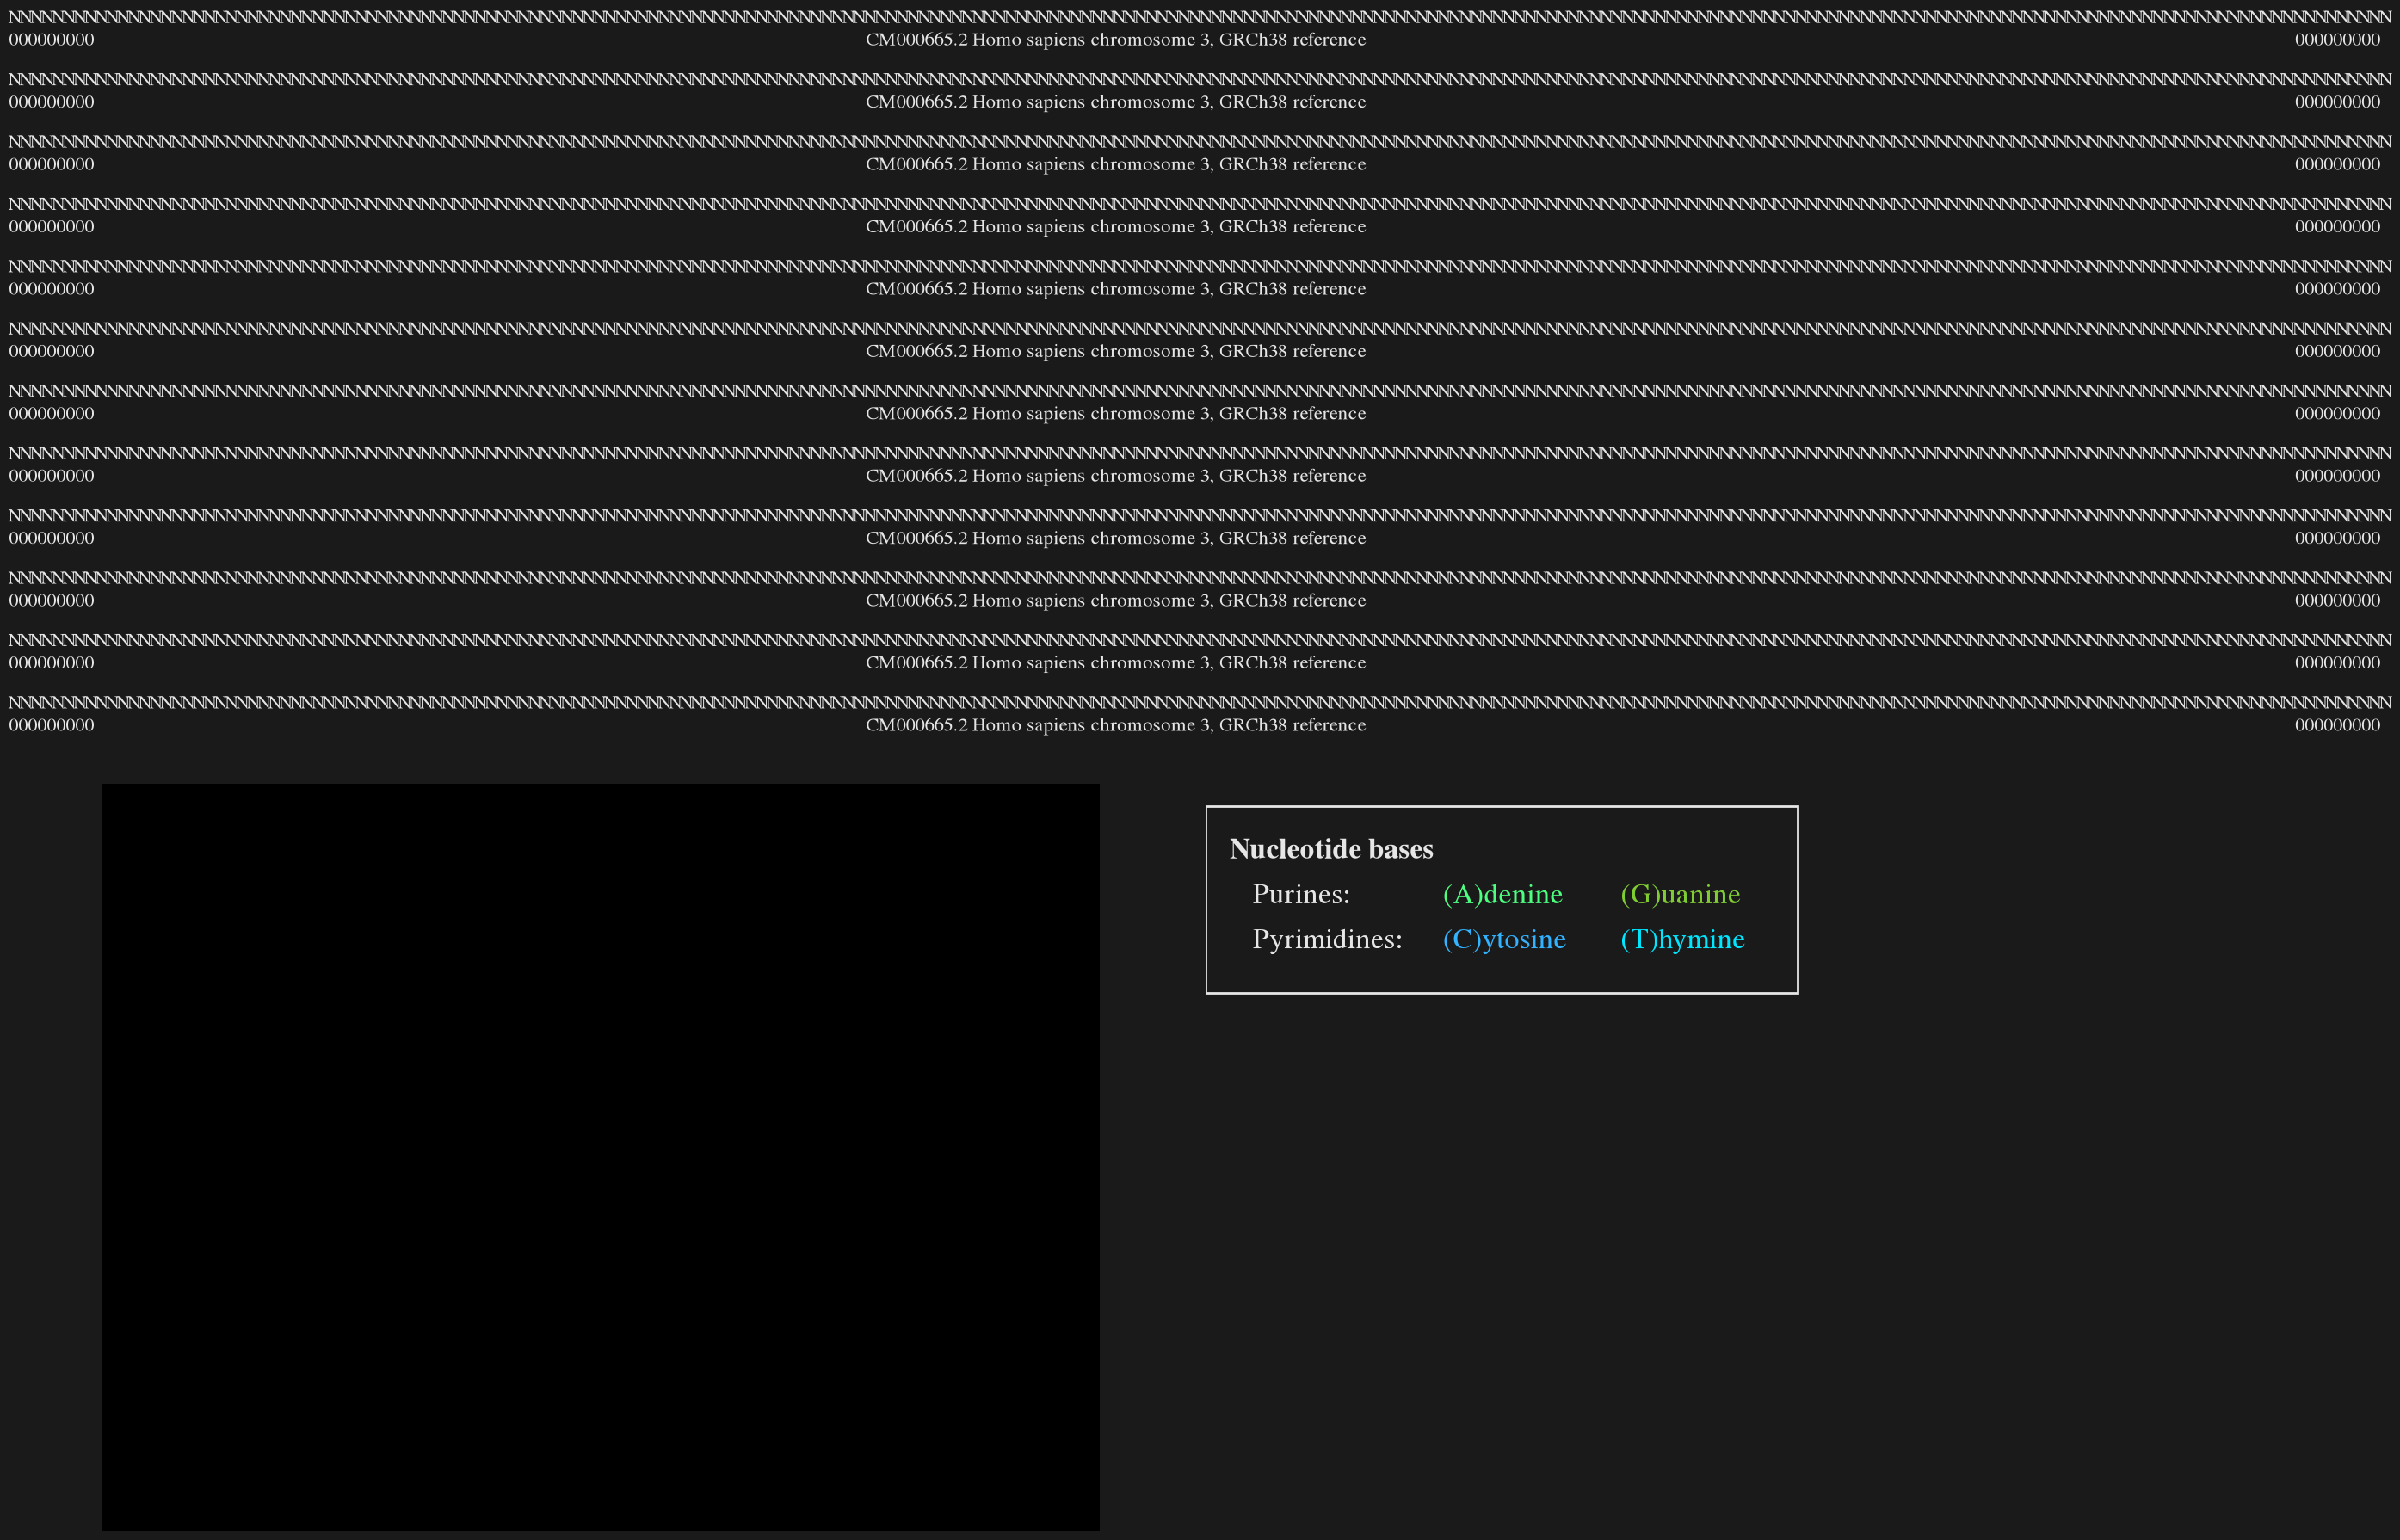

In [198]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Rectangle
import matplotlib.animation as animation
import numpy as np

plt.rcParams['font.family'] = 'STIXGeneral'

fig = plt.figure(layout="tight", figsize=(28, 18), facecolor=BACKGROUND_COLOR)

ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
ax2 = plt.subplot2grid((2, 2), (1, 0))
ax3 = plt.subplot2grid((2, 2), (1, 1))

axs = [ax1, ax2, ax3]

for ax in axs:    
    ax.axis("off")

fig_sequences = []
for y in range(HEIGHT):
    fig_sequences.append(SequenceDraw(axs[0], y))

img = mpimg.imread("frames/frame0001.png") 
axs[1].imshow(img)

# Replace if groups 1 and 2 are not purines and pyrimidines
axs[2].add_patch(Rectangle((0, 0.72), 0.5, 0.25, edgecolor=TEXT_COLOR, fill=False, lw=2))
axs[2].text(0.02, 0.9, "Nucleotide bases", fontsize=24, color=TEXT_COLOR, fontweight="bold")
axs[2].text(0.04, 0.84, "Purines:", fontsize=24, color=TEXT_COLOR)
axs[2].text(0.2, 0.84, "(A)denine", fontsize=24, color=BASE_COLORS["A"])
axs[2].text(0.35, 0.84, "(G)uanine", fontsize=24, color=BASE_COLORS["G"])
axs[2].text(0.04, 0.78, "Pyrimidines:", fontsize=24, color=TEXT_COLOR)
axs[2].text(0.2, 0.78, "(C)ytosine", fontsize=24, color=BASE_COLORS["C"])
axs[2].text(0.35, 0.78, "(T)hymine", fontsize=24, color=BASE_COLORS["T"])

## Perform global/local alignment with Needleman-Wunsch

In [35]:
%%bash
mkdir -p outputs
cp queries/meta.json outputs/meta.json
. align.sh

Output for queries/query_0000.fa already found, skipping
Output for queries/query_0001.fa already found, skipping
Output for queries/query_0002.fa already found, skipping
Output for queries/query_0003.fa already found, skipping
Output for queries/query_0004.fa already found, skipping
Output for queries/query_0005.fa already found, skipping
Output for queries/query_0006.fa already found, skipping
Output for queries/query_0007.fa already found, skipping
Output for queries/query_0008.fa already found, skipping
Output for queries/query_0009.fa already found, skipping
Output for queries/query_0010.fa already found, skipping
Output for queries/query_0011.fa already found, skipping
Output for queries/query_0012.fa already found, skipping
Output for queries/query_0013.fa already found, skipping
Output for queries/query_0014.fa already found, skipping
Output for queries/query_0015.fa already found, skipping
Output for queries/query_0016.fa already found, skipping
Output for queries/query_0017.f

Output for queries/query_0144.fa already found, skipping
Output for queries/query_0145.fa already found, skipping
Output for queries/query_0146.fa already found, skipping
Output for queries/query_0147.fa already found, skipping
Output for queries/query_0148.fa already found, skipping
Output for queries/query_0149.fa already found, skipping
Output for queries/query_0150.fa already found, skipping
Output for queries/query_0151.fa already found, skipping
Output for queries/query_0152.fa already found, skipping
Output for queries/query_0153.fa already found, skipping
Output for queries/query_0154.fa already found, skipping
Output for queries/query_0155.fa already found, skipping
Output for queries/query_0156.fa already found, skipping
Output for queries/query_0157.fa already found, skipping
Output for queries/query_0158.fa already found, skipping
Output for queries/query_0159.fa already found, skipping
Output for queries/query_0160.fa already found, skipping
Output for queries/query_0161.f

Output for queries/query_0288.fa already found, skipping
Output for queries/query_0289.fa already found, skipping
Output for queries/query_0290.fa already found, skipping
Output for queries/query_0291.fa already found, skipping
Output for queries/query_0292.fa already found, skipping
Output for queries/query_0293.fa already found, skipping
Output for queries/query_0294.fa already found, skipping
Output for queries/query_0295.fa already found, skipping
Output for queries/query_0296.fa already found, skipping
Output for queries/query_0297.fa already found, skipping
Output for queries/query_0298.fa already found, skipping
Output for queries/query_0299.fa already found, skipping
Output for queries/query_0300.fa already found, skipping
Output for queries/query_0301.fa already found, skipping
Output for queries/query_0302.fa already found, skipping
Output for queries/query_0303.fa already found, skipping
Output for queries/query_0304.fa already found, skipping
Output for queries/query_0305.f

Output for queries/query_0432.fa already found, skipping
Output for queries/query_0433.fa already found, skipping
Output for queries/query_0434.fa already found, skipping
Output for queries/query_0435.fa already found, skipping
Output for queries/query_0436.fa already found, skipping
Output for queries/query_0437.fa already found, skipping
Output for queries/query_0438.fa already found, skipping
Output for queries/query_0439.fa already found, skipping
Output for queries/query_0440.fa already found, skipping
Output for queries/query_0441.fa already found, skipping
Output for queries/query_0442.fa already found, skipping
Output for queries/query_0443.fa already found, skipping
Output for queries/query_0444.fa already found, skipping
Output for queries/query_0445.fa already found, skipping
Output for queries/query_0446.fa already found, skipping
Output for queries/query_0447.fa already found, skipping
Output for queries/query_0448.fa already found, skipping
Output for queries/query_0449.f

Output for queries/query_0576.fa already found, skipping
Output for queries/query_0577.fa already found, skipping
Output for queries/query_0578.fa already found, skipping
Output for queries/query_0579.fa already found, skipping
Output for queries/query_0580.fa already found, skipping
Output for queries/query_0581.fa already found, skipping
Output for queries/query_0582.fa already found, skipping
Output for queries/query_0583.fa already found, skipping
Output for queries/query_0584.fa already found, skipping
Output for queries/query_0585.fa already found, skipping
Output for queries/query_0586.fa already found, skipping
Output for queries/query_0587.fa already found, skipping
Output for queries/query_0588.fa already found, skipping
Output for queries/query_0589.fa already found, skipping
Output for queries/query_0590.fa already found, skipping
Output for queries/query_0591.fa already found, skipping
Output for queries/query_0592.fa already found, skipping
Output for queries/query_0593.f

...

===
Aligning to queries/query_1822.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1822.output
Successes: 342, Fails: 0
Total time: 63948, Count: 342, Average time: 186
===
Aligning to queries/query_1823.fa
Succeeded in finding alignment in 179 seconds to outputs/fasta_1823.output
Successes: 343, Fails: 0
Total time: 64127, Count: 343, Average time: 186
===
Aligning to queries/query_1824.fa
Succeeded in finding alignment in 183 seconds to outputs/fasta_1824.output
Successes: 344, Fails: 0
Total time: 64310, Count: 344, Average time: 186
===
Aligning to queries/query_1825.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1825.output
Successes: 345, Fails: 0
Total time: 64484, Count: 345, Average time: 186
===
Aligning to queries/query_1826.fa
Succeeded in finding alignment in 175 seconds to outputs/fasta_1826.output
Successes: 346, Fails: 0
Total time: 64659, Count: 346, Average time: 186
===
Aligning to queries/query_1827.fa
Succeeded in finding alignm

===
Aligning to queries/query_1866.fa
Succeeded in finding alignment in 172 seconds to outputs/fasta_1866.output
Successes: 386, Fails: 0
Total time: 71642, Count: 386, Average time: 185
===
Aligning to queries/query_1867.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1867.output
Successes: 387, Fails: 0
Total time: 71816, Count: 387, Average time: 185
===
Aligning to queries/query_1868.fa
Succeeded in finding alignment in 176 seconds to outputs/fasta_1868.output
Successes: 388, Fails: 0
Total time: 71992, Count: 388, Average time: 185
===
Aligning to queries/query_1869.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1869.output
Successes: 389, Fails: 0
Total time: 72165, Count: 389, Average time: 185
===
Aligning to queries/query_1870.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1870.output
Successes: 390, Fails: 0
Total time: 72339, Count: 390, Average time: 185
===
Aligning to queries/query_1871.fa
Succeeded in finding alignm

===
Aligning to queries/query_1910.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1910.output
Successes: 430, Fails: 0
Total time: 79341, Count: 430, Average time: 184
===
Aligning to queries/query_1911.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1911.output
Successes: 431, Fails: 0
Total time: 79514, Count: 431, Average time: 184
===
Aligning to queries/query_1912.fa
Succeeded in finding alignment in 172 seconds to outputs/fasta_1912.output
Successes: 432, Fails: 0
Total time: 79686, Count: 432, Average time: 184
===
Aligning to queries/query_1913.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1913.output
Successes: 433, Fails: 0
Total time: 79859, Count: 433, Average time: 184
===
Aligning to queries/query_1914.fa
Succeeded in finding alignment in 172 seconds to outputs/fasta_1914.output
Successes: 434, Fails: 0
Total time: 80031, Count: 434, Average time: 184
===
Aligning to queries/query_1915.fa
Succeeded in finding alignm

===
Aligning to queries/query_1954.fa
Succeeded in finding alignment in 174 seconds to outputs/fasta_1954.output
Successes: 474, Fails: 0
Total time: 87025, Count: 474, Average time: 183
===
Aligning to queries/query_1955.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1955.output
Successes: 475, Fails: 0
Total time: 87198, Count: 475, Average time: 183
===
Aligning to queries/query_1956.fa
Succeeded in finding alignment in 177 seconds to outputs/fasta_1956.output
Successes: 476, Fails: 0
Total time: 87375, Count: 476, Average time: 183
===
Aligning to queries/query_1957.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1957.output
Successes: 477, Fails: 0
Total time: 87548, Count: 477, Average time: 183
===
Aligning to queries/query_1958.fa
Succeeded in finding alignment in 173 seconds to outputs/fasta_1958.output
Successes: 478, Fails: 0
Total time: 87721, Count: 478, Average time: 183
===
Aligning to queries/query_1959.fa
Succeeded in finding alignm

kill: usage: kill [-s sigspec | -n signum | -sigspec] pid | jobspec ... or kill -l [sigspec]


## Parse readable output into `.json` write to disk

In [1]:
from output_parser import parse_to_json_files
parse_to_json_files()

Parsing outputs\fasta_0000.output
Parsing outputs\fasta_0001.output
Parsing outputs\fasta_0002.output
Parsing outputs\fasta_0003.output
Parsing outputs\fasta_0004.output
Parsing outputs\fasta_0005.output
Parsing outputs\fasta_0006.output
Parsing outputs\fasta_0007.output
Parsing outputs\fasta_0008.output
Parsing outputs\fasta_0009.output
Parsing outputs\fasta_0010.output
Parsing outputs\fasta_0011.output
Parsing outputs\fasta_0012.output
Parsing outputs\fasta_0013.output
Parsing outputs\fasta_0014.output
Parsing outputs\fasta_0015.output
Parsing outputs\fasta_0016.output
Parsing outputs\fasta_0017.output
Parsing outputs\fasta_0018.output
Parsing outputs\fasta_0019.output
Parsing outputs\fasta_0020.output
Parsing outputs\fasta_0021.output
Parsing outputs\fasta_0022.output
Parsing outputs\fasta_0023.output
Parsing outputs\fasta_0024.output
Parsing outputs\fasta_0025.output
Parsing outputs\fasta_0026.output
Parsing outputs\fasta_0027.output
Parsing outputs\fasta_0028.output
Parsing output

## Extract renderable sequences with rev-comp applied where needed

In [199]:
import glob
import json

line_cache = {}

for filename in glob.glob("outputs/fasta_*.json"):
    index = int(filename[14:-5])
    with open(filename, "r") as f:
        line_cache[index] = json.loads(f.read())

frames = []

for filename in sorted(glob.glob("queries/frame_*.json")):
    index = int(filename[14:-5])
    with open(filename, "r") as f:
        frame = json.loads(f.read())
        frame["index"] = index
        frames.append(frame)

print(len(line_cache) + len(frames), "files loaded")
    

2197 files loaded


In [200]:
def get_sequence(data):
    if data["status"] != "Sequence found":
        return ""
    s = data["sequence"]
    if data["rev-comp"]:
        s = s[::-1].replace("A", "_").replace("T", "A").replace("_", "T").replace("C", "_").replace("G", "C").replace("_", "G")
    return s

def normalize(data):
    data["sequence"] = get_sequence(data)
    data["sequence"] = (data["sequence"] + ("-" * (WIDTH - len(data["sequence"]))))[:WIDTH]
    if data["status"] != "Sequence found":
        return data
    if data["rev-comp"]:
        tmp = data["range"]["from"]
        data["range"]["from"] = data["range"]["to"]
        data["range"]["to"] = tmp
        data["name"] += ", reverse complement"
    return data

def fit_to_width(data):
    return data
    

In [201]:
for index in line_cache.keys():
    line_cache[index] = normalize(line_cache[index])
    line_cache[index] = fit_to_width(line_cache[index])
    

Drawing frame 0 of 219

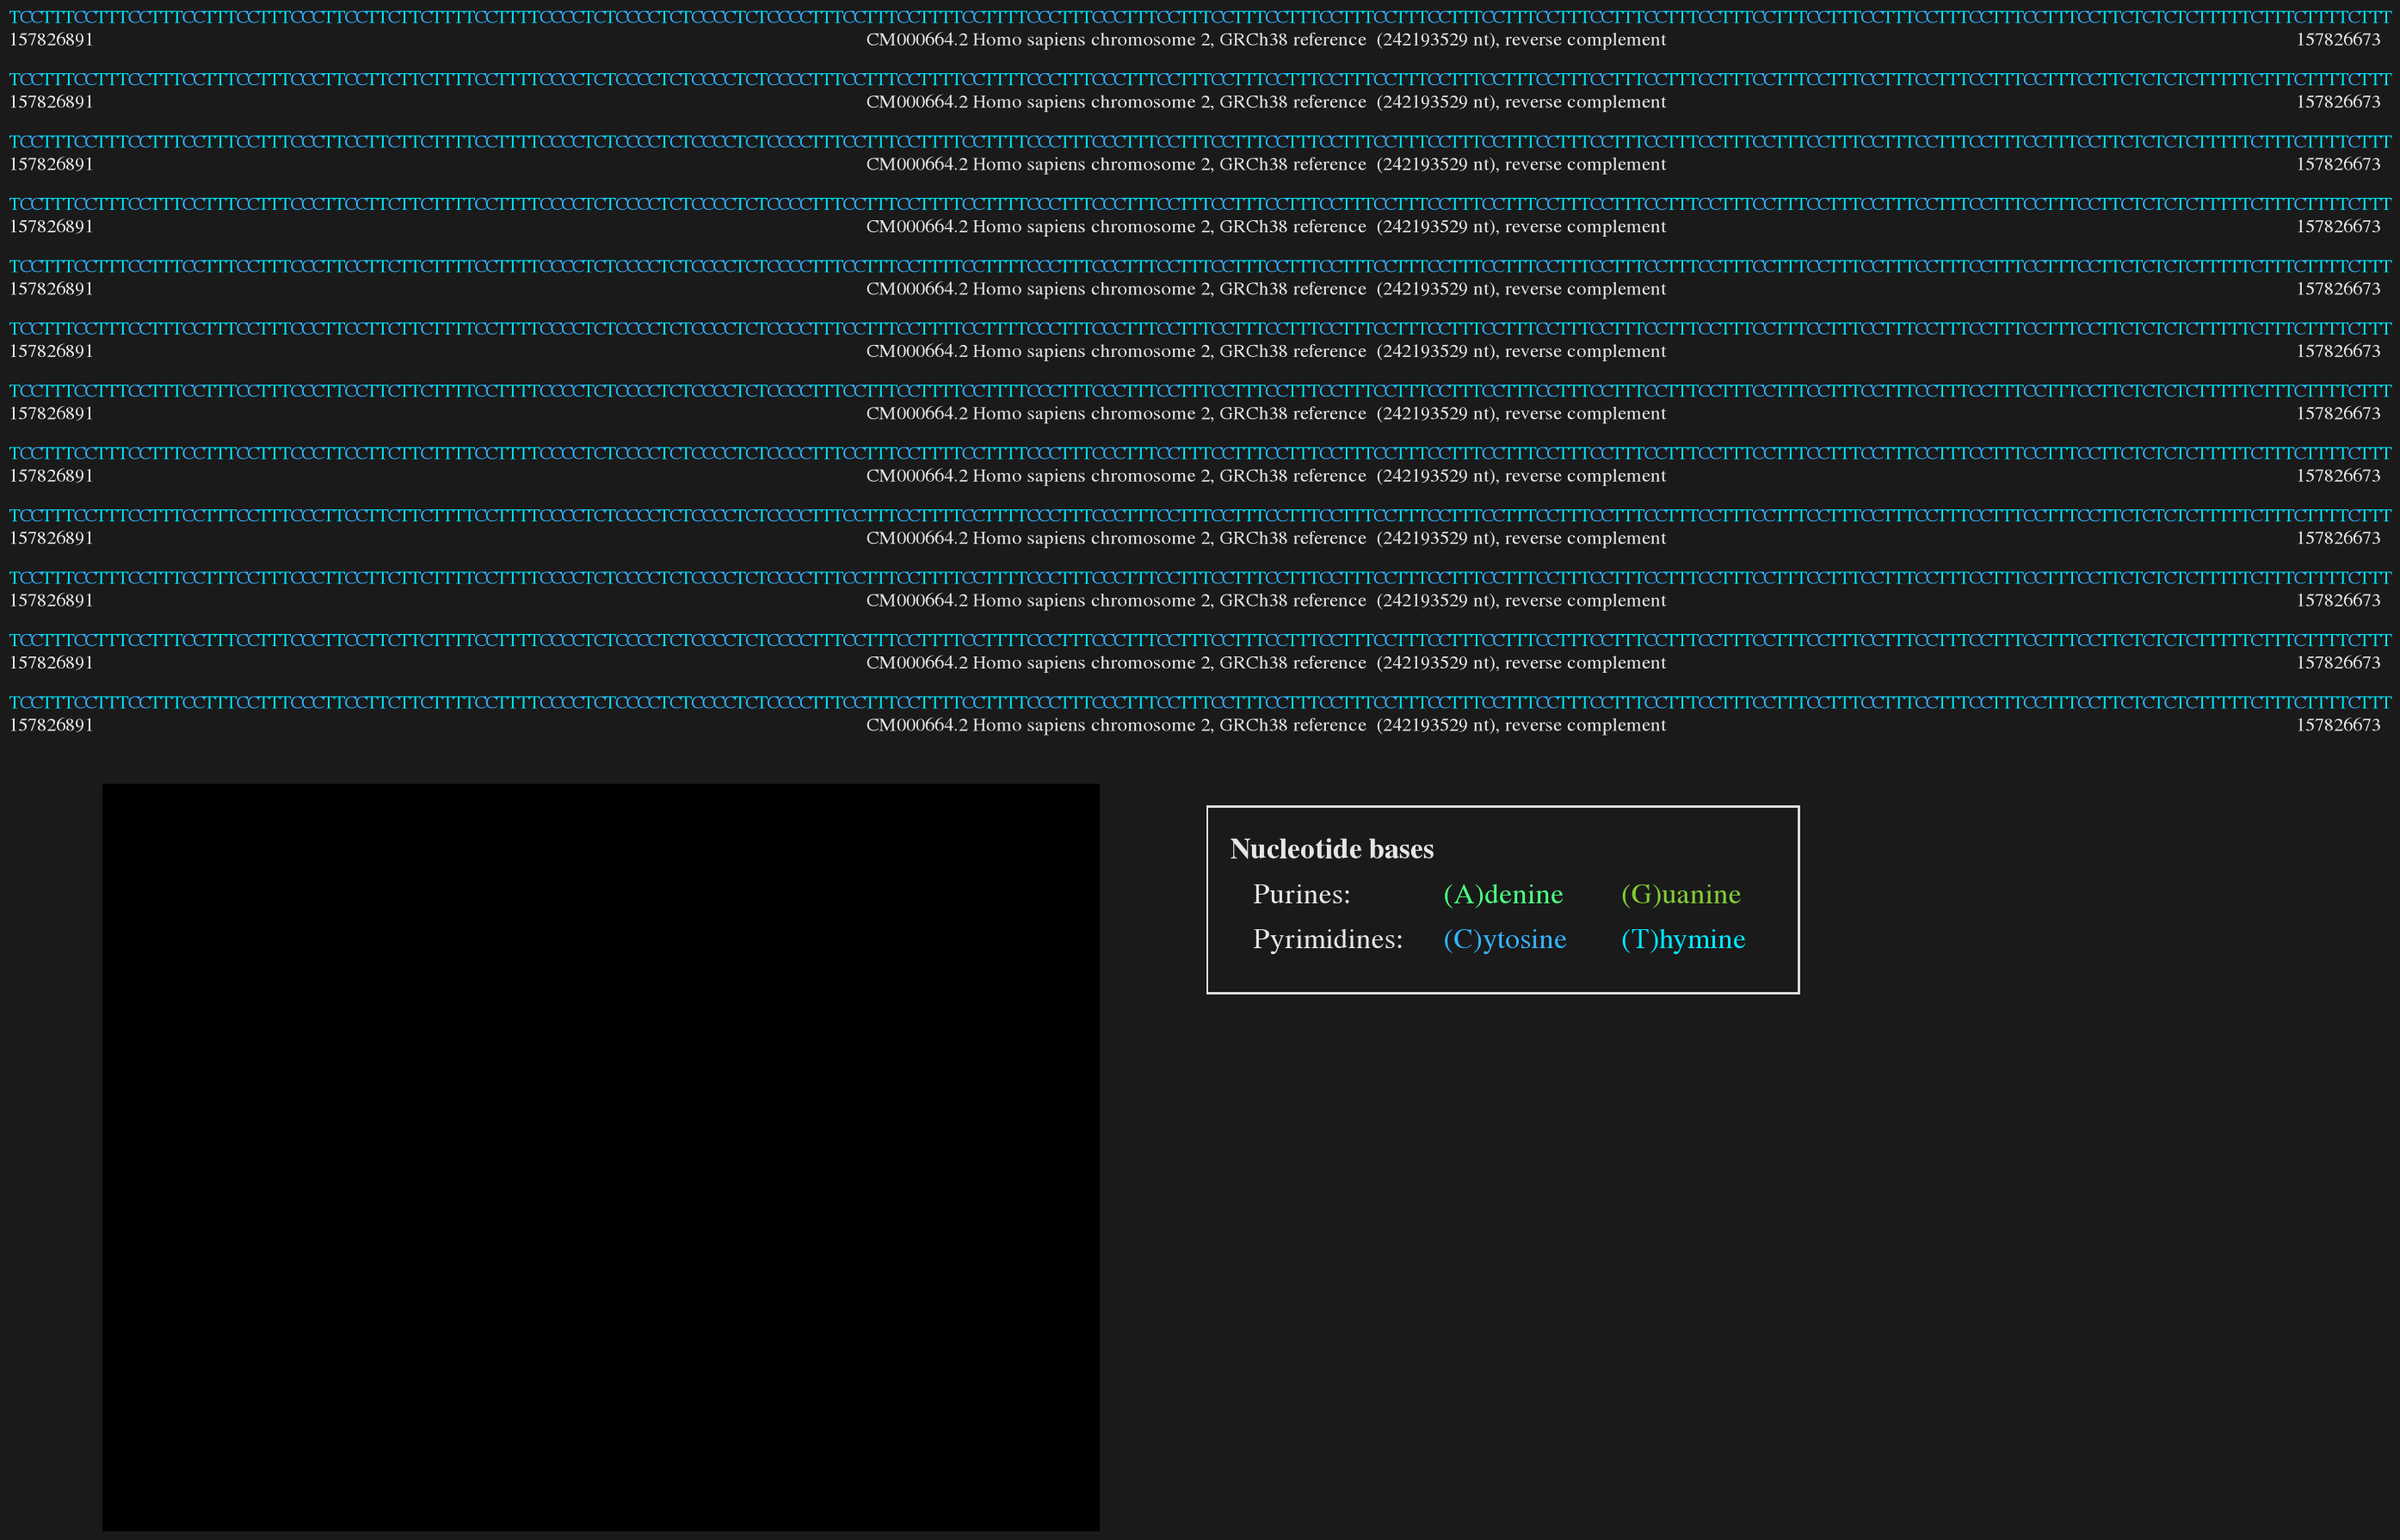

In [202]:
def draw(i):
    print(f"Drawing frame {i} of {FRAMES*FPS//24}", end="\r", flush=True)
    lines = frames[i]["lines"]
    y = 0
    for line in lines:
        data = line_cache[line]
        fig_sequences[y].write_info(data["name"], data["range"]["from"], data["range"]["to"])
        x = 0
        for base in data["sequence"]:
            fig_sequences[y].write_char(base, x)
            x += 1
        y += 1
        
    axs[1].clear()
    axs[1].axis("off")
    
    img = mpimg.imread(f"frames/frame{frames[i]["index"]:04d}.png") 
    axs[1].imshow(img)

draw(0)
fig

## Save video `.mp4` and replay

Drawing frame 218 of 219

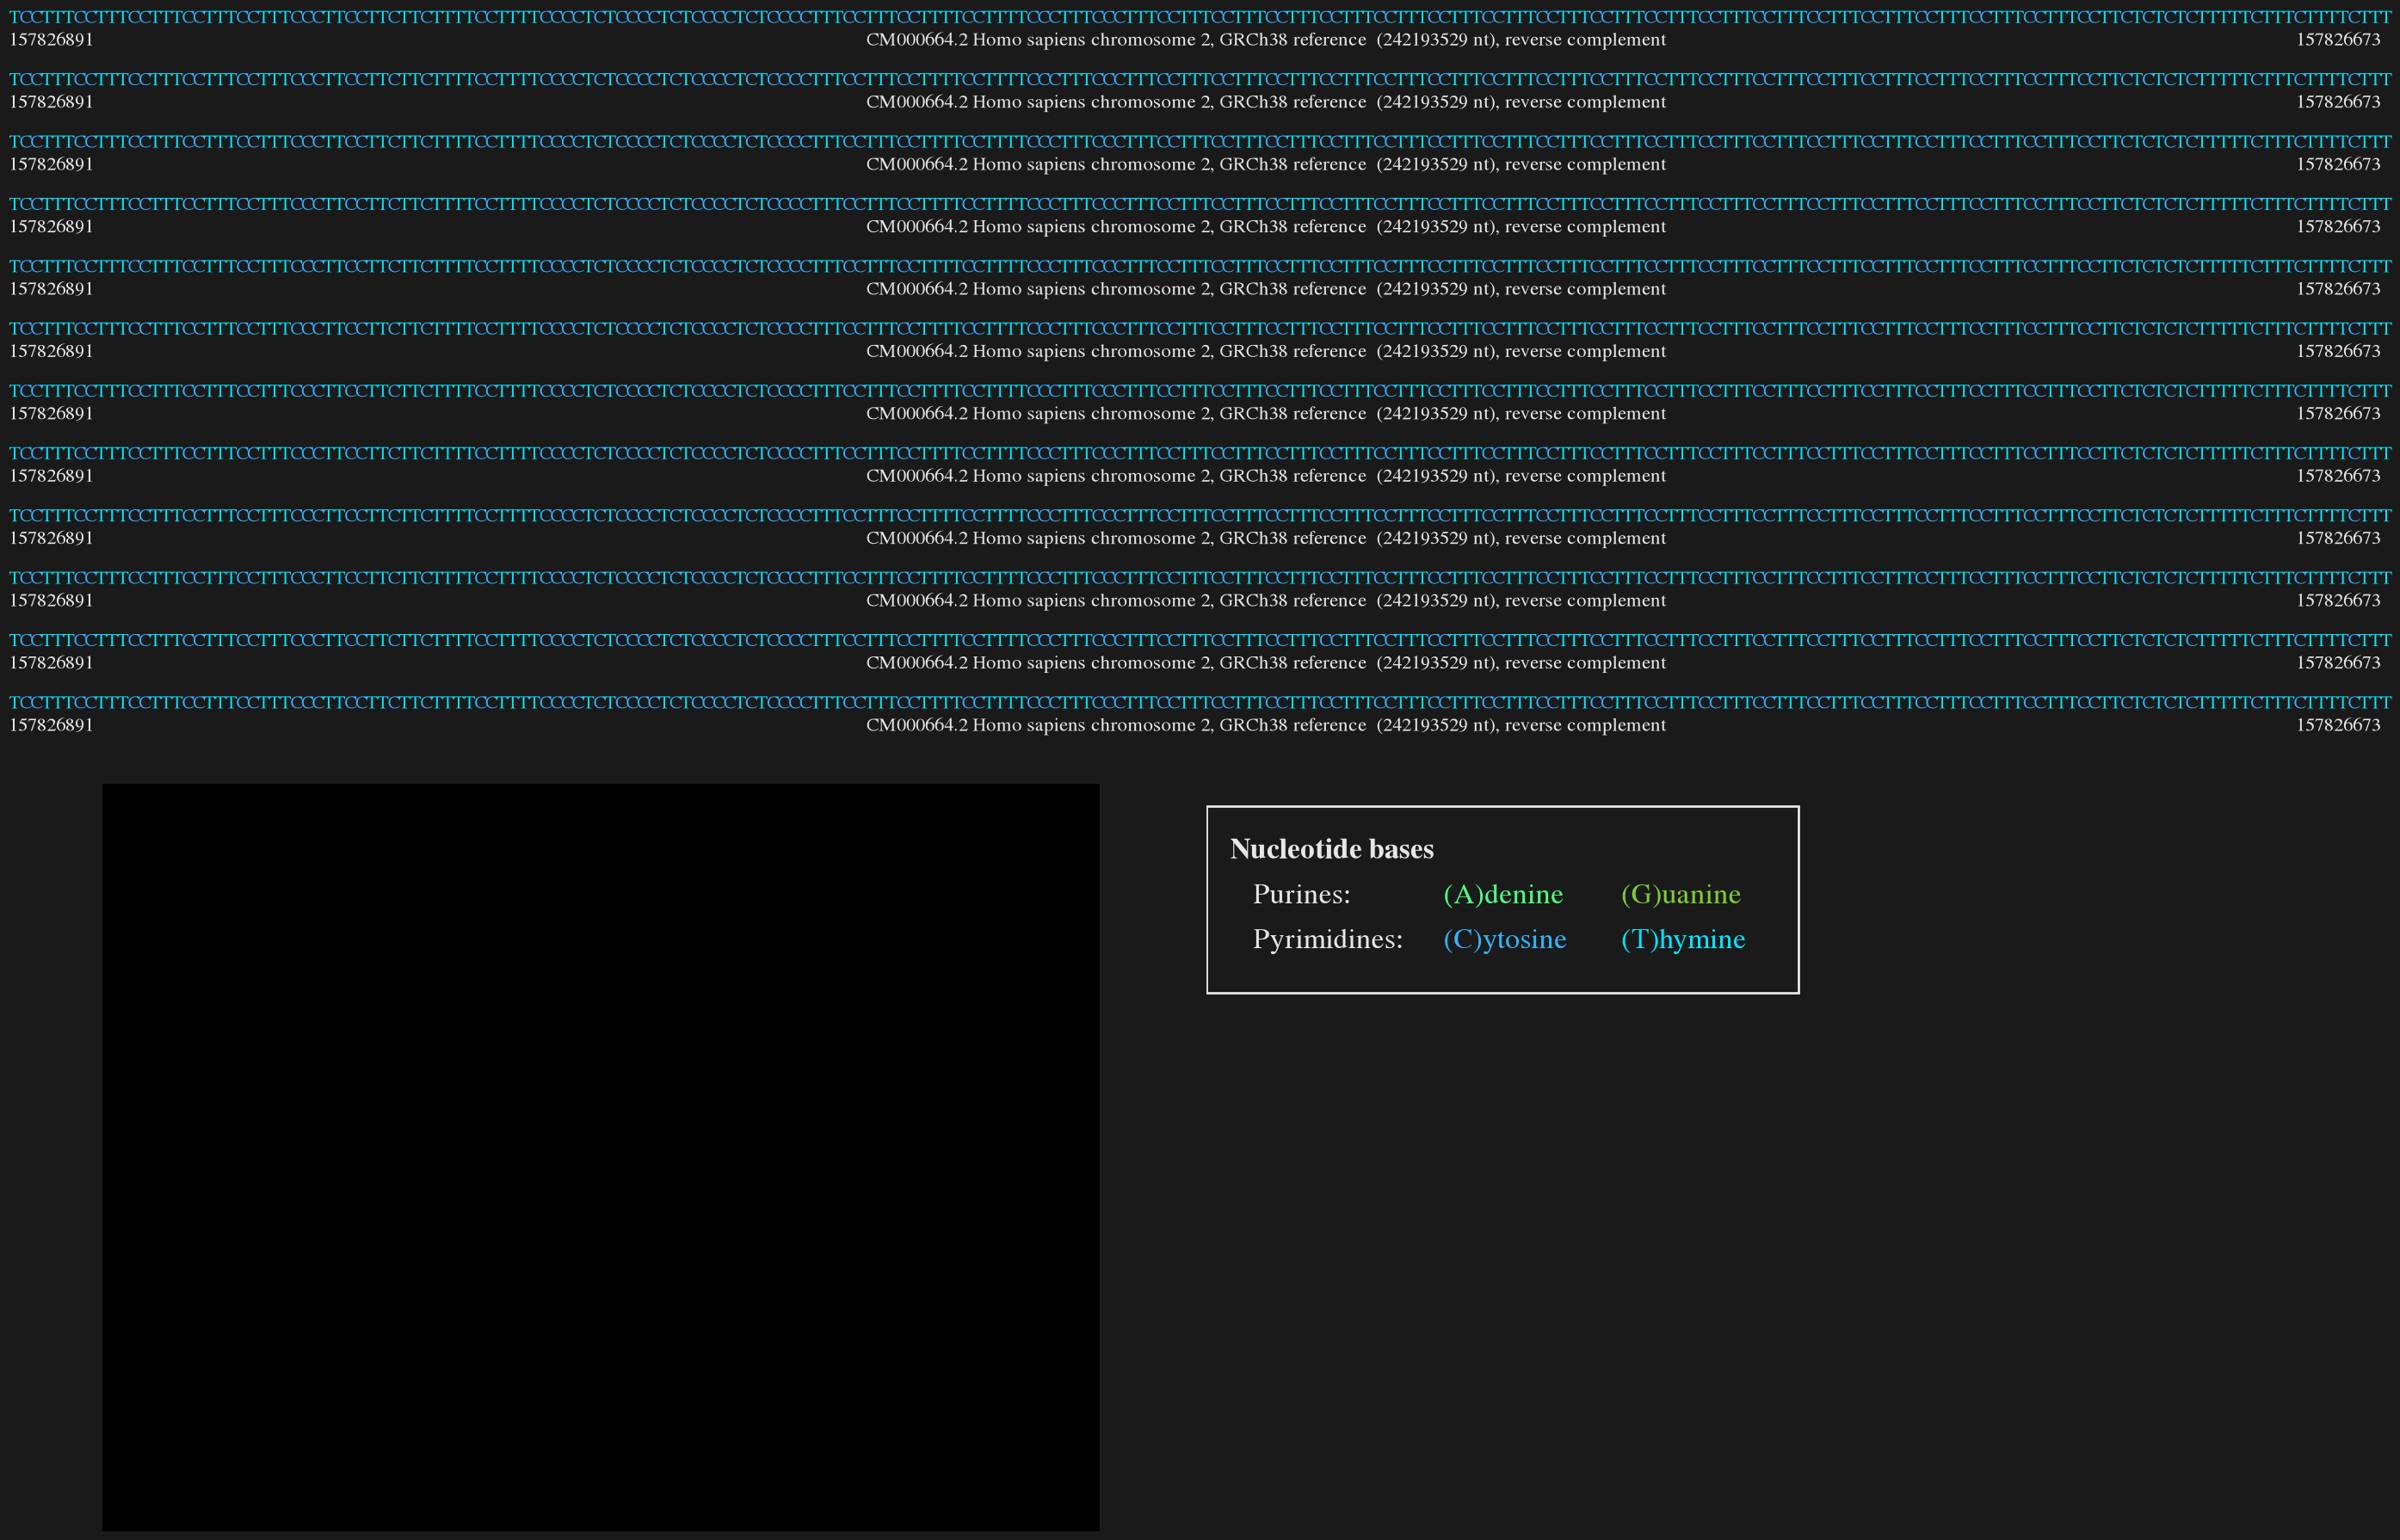

In [203]:
ani = animation.FuncAnimation(fig=fig, func=draw, frames=FRAMES*FPS//24, interval=1)

FFwriter = animation.FFMpegWriter(fps=FPS)
ani.save('animation.mp4', writer=FFwriter)
fig

In [204]:
from IPython.display import Video
Video("animation.mp4")

In [205]:
del ani
plt.close(fig)